# Titanic Survival Analysis — Exploratory Data Analysis

## Project Objective
The objective of this project is to explore the Titanic passenger dataset, identify patterns in passenger survival, investigate missing values, and understand how factors such as gender, passenger class, fare, age, and family size relate to survival.

## Dataset
The dataset contains information about 891 Titanic passengers and 12 original columns.

## Tools and Technologies
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Jupyter Notebook

## Key Questions
1. How did survival rates differ between male and female passengers?
2. How was passenger class associated with survival?
3. What relationship existed between ticket fare and survival?
4. How did family size relate to survival?
5. Which columns contained missing values, and how could they be handled?

## 1. Import Libraries

In [61]:
import  numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

## 2. Load Dataset

In [62]:
df = pd.read_csv('train.csv')

In [63]:
df


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


## 3. Data Overview

In [64]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [65]:
df.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='str')

In [66]:
df.shape

(891, 12)

In [67]:
df.info

<bound method DataFrame.info of      PassengerId  Survived  Pclass  \
0              1         0       3   
1              2         1       1   
2              3         1       3   
3              4         1       1   
4              5         0       3   
..           ...       ...     ...   
886          887         0       2   
887          888         1       1   
888          889         0       3   
889          890         1       1   
890          891         0       3   

                                                  Name     Sex   Age  SibSp  \
0                              Braund, Mr. Owen Harris    male  22.0      1   
1    Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                               Heikkinen, Miss. Laina  female  26.0      0   
3         Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                             Allen, Mr. William Henry    male  35.0      0   
..                                   

## 4. Data Cleaning

In [68]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

## 5. Exploratory Data Analysis (EDA)

In [69]:
df['Survived'].value_counts()

Survived
0    549
1    342
Name: count, dtype: int64

In [70]:
df.groupby('Sex')['Survived'].mean()*100

Sex
female    74.203822
male      18.890815
Name: Survived, dtype: float64

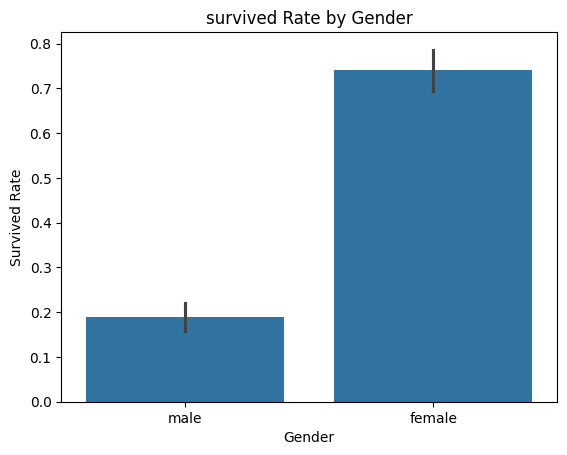

In [71]:
sns.barplot(data=df,x='Sex',y='Survived')
plt.title("survived Rate by Gender")
plt.ylabel('Survived Rate')
plt.xlabel('Gender')

plt.show()

In [72]:
df.groupby('Pclass')['Survived'].mean()*100

Pclass
1    62.962963
2    47.282609
3    24.236253
Name: Survived, dtype: float64

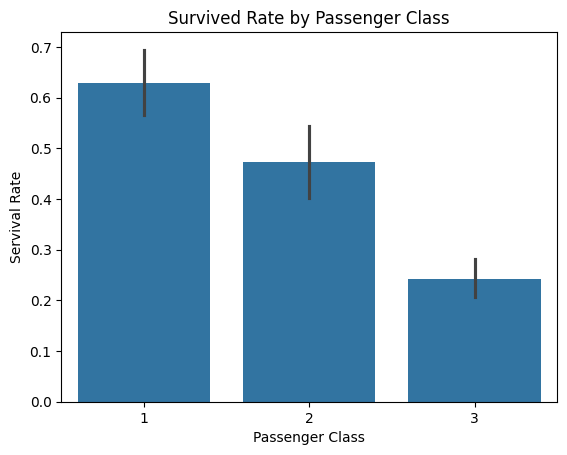

In [73]:
sns.barplot(data=df,y='Survived',x='Pclass')

plt.title('Survived Rate by Passenger Class')
plt.ylabel('Servival Rate')
plt.xlabel('Passenger Class')

plt.show()

In [74]:
df.groupby(["Sex","Pclass"])['Survived'].mean()*100

Sex     Pclass
female  1         96.808511
        2         92.105263
        3         50.000000
male    1         36.885246
        2         15.740741
        3         13.544669
Name: Survived, dtype: float64

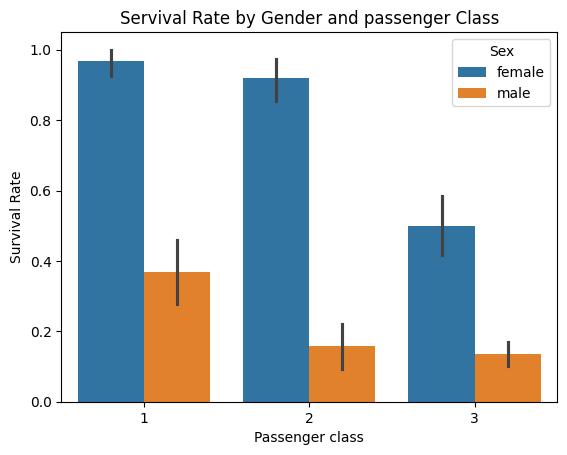

In [75]:
sns.barplot(
    data=df,
    x= "Pclass",
    y = "Survived",
    hue= "Sex"
    )


plt.title("Servival Rate by Gender and passenger Class")
plt.xlabel("Passenger class")
plt.ylabel("Survival Rate")
plt.show()

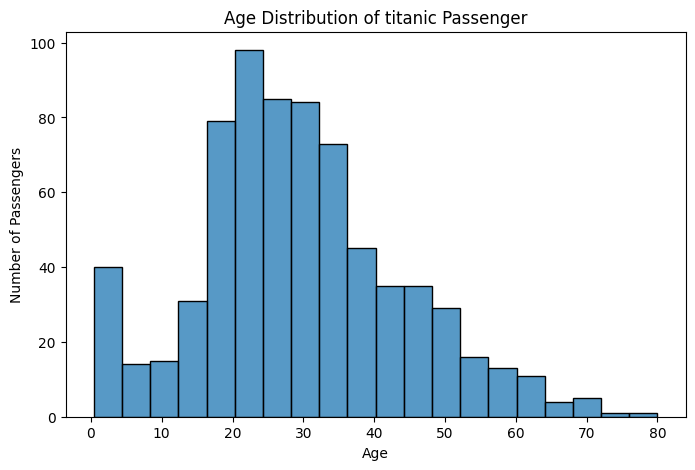

In [76]:
plt.figure(figsize=(8,5))

sns.histplot(data=df,x="Age",bins = 20)

plt.title("Age Distribution of titanic Passenger")
plt.xlabel("Age")
plt.ylabel("Number of Passengers")
plt.show()

In [77]:
df["AgeGroup"] = pd.cut(
    df["Age"],
    bins=[0, 12, 18, 35, 60, 100],
    labels=["Child", "Teenager", "Adult", "Middle-aged", "Senior"]
)

df.groupby("AgeGroup", observed=True)["Survived"].mean() * 100

AgeGroup
Child          57.971014
Teenager       42.857143
Adult          38.268156
Middle-aged    40.000000
Senior         22.727273
Name: Survived, dtype: float64

In [78]:
df["Fare"].describe()

count    891.000000
mean      32.204208
std       49.693429
min        0.000000
25%        7.910400
50%       14.454200
75%       31.000000
max      512.329200
Name: Fare, dtype: float64

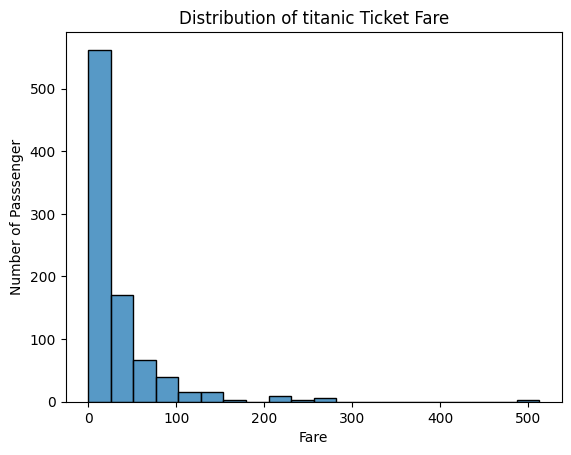

In [79]:
sns.histplot(
    data = df,
    x= 'Fare',
    bins = 20 
)

plt.title('Distribution of titanic Ticket Fare')
plt.xlabel("Fare")
plt.ylabel('Number of Passsenger')

plt.show()

In [80]:
Q1 = df["Fare"].quantile(0.25)
Q3 = df["Fare"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = df[
    (df["Fare"] < lower) |
    (df["Fare"] > upper)
]

print("Lower limit:", lower)
print("Upper limit:", upper)
print("Total outliers:", len(outliers))

Lower limit: -26.724
Upper limit: 65.6344
Total outliers: 116


In [81]:
outliers[["Name", "Pclass", "Fare"]].sort_values(
    by="Fare",
    ascending=False
).head(10)

,Name,Pclass,Fare
258,"Ward, Miss. Anna",1,512.3292
737,"Lesurer, Mr. Gustave J",1,512.3292
679,"Cardeza, Mr. Thomas Drake Martinez",1,512.3292
27,"Fortune, Mr. Charles Alexander",1,263.0000
341,"Fortune, Miss. Alice Elizabeth",1,263.0000
438,"Fortune, Mr. Mark",1,263.0000
88,"Fortune, Miss. Mabel Helen",1,263.0000
311,"Ryerson, Miss. Emily Borie",1,262.3750
742,"Ryerson, Miss. Susan Parker ""Suzette""",1,262.3750
299,"Baxter, Mrs. James (Helene DeLaudeniere Chaput)",1,247.5208


In [82]:
df.groupby("Pclass")["Fare"].agg(
    ["mean", "median", "min", "max"]
).round(2)


,mean,median,min,max
Pclass,,,,
1,84.15,60.29,0.0,512.33
2,20.66,14.25,0.0,73.50
3,13.68,8.05,0.0,69.55


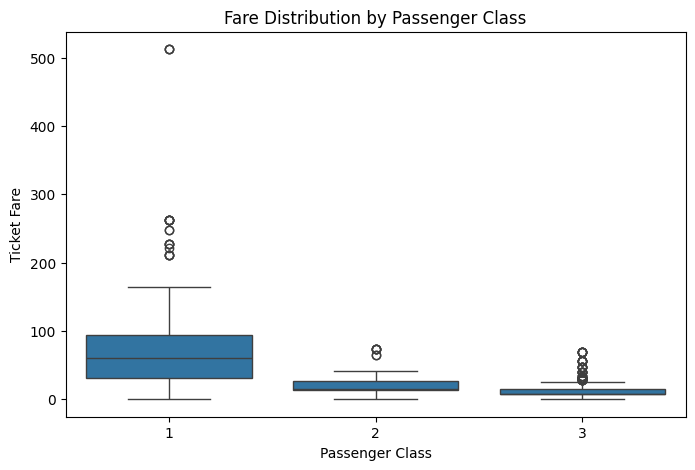

In [83]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="Pclass", y="Fare")

plt.title("Fare Distribution by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Ticket Fare")

plt.show()

In [84]:
df.groupby('Pclass')['Fare'].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
Pclass,,,,,,,,
1,216.0,84.15,78.38,0.0,30.92,60.29,93.5,512.33
2,184.0,20.66,13.42,0.0,13.00,14.25,26.0,73.50
3,491.0,13.68,11.78,0.0,7.75,8.05,15.5,69.55


In [85]:
corr = df[["Survived", "Pclass", "Age", "SibSp", "Parch", "Fare"]].corr()

print(corr["Survived"].sort_values(ascending=False))

Survived    1.000000
Fare        0.257307
Parch       0.081629
SibSp      -0.035322
Age        -0.077221
Pclass     -0.338481
Name: Survived, dtype: float64


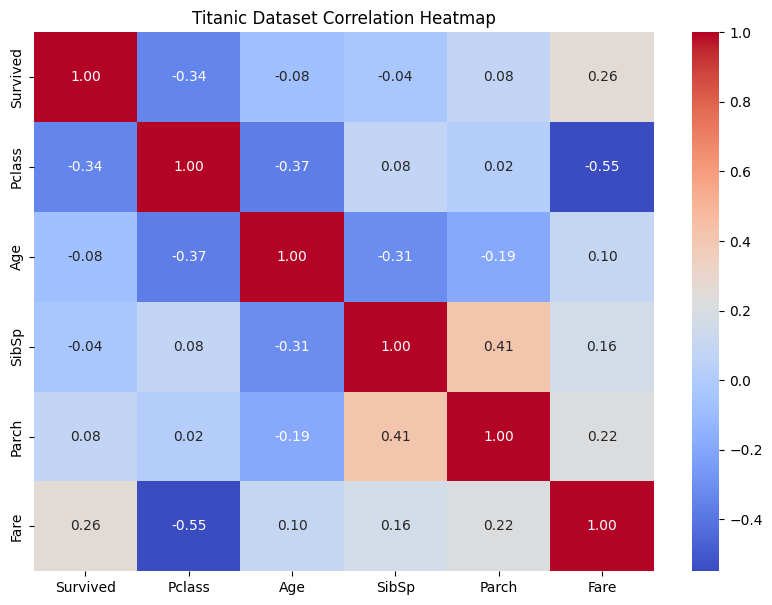

In [86]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Titanic Dataset Correlation Heatmap")
plt.show()

In [87]:
missing = df.isnull().sum()
missing_percent = (df.isnull().sum() / len(df)) * 100

missing_report = pd.DataFrame({
    "Missing_Count": missing,
    "Missing_Percentage": missing_percent
})

print(missing_report[missing_report["Missing_Count"] > 0].sort_values(
    "Missing_Percentage", ascending=False
).round(2))


          Missing_Count  Missing_Percentage
Cabin               687               77.10
Age                 177               19.87
AgeGroup            177               19.87
Embarked              2                0.22


In [88]:
df["Age"].describe()

count    714.000000
mean      29.699118
std       14.526497
min        0.420000
25%       20.125000
50%       28.000000
75%       38.000000
max       80.000000
Name: Age, dtype: float64

In [89]:
print("Mean Age:", df["Age"].mean())
print("Median Age:", df["Age"].median())

Mean Age: 29.69911764705882
Median Age: 28.0


In [90]:
df["Age"] = df["Age"].fillna(df["Age"].median())

In [91]:
print(df["Age"].isnull().sum())

0


In [92]:
df["AgeGroup"] = pd.cut(
    df["Age"],
    bins=[0, 12, 18, 35, 60, 100],
    labels=["Child", "Teenager", "Adult", "Middle-aged", "Senior"]
)

In [93]:
print(df["Embarked"].value_counts())
print("Most common:", df["Embarked"].mode()[0])

Embarked
S    644
C    168
Q     77
Name: count, dtype: int64
Most common: S


In [94]:
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])

In [95]:
print(df["Embarked"].isnull().sum())

0


In [96]:
df["HasCabin"] = df["Cabin"].notna().astype(int)

df.groupby("HasCabin")["Survived"].mean() * 100

HasCabin
0    29.985444
1    66.666667
Name: Survived, dtype: float64

In [97]:
pd.crosstab(
    df["Pclass"],
    df["HasCabin"],
    normalize="index"
).round(3) * 100

HasCabin,0,1
Pclass,,
1,18.5,81.5
2,91.3,8.7
3,97.6,2.4


In [98]:
df.groupby(['Pclass','HasCabin'])['Survived'].mean().mul(100).round(2)

Pclass  HasCabin
1       0           47.50
        1           66.48
2       0           44.05
        1           81.25
3       0           23.59
        1           50.00
Name: Survived, dtype: float64

## 6. Feature Engineering

In [99]:

df["FamilySize"] = df["SibSp"] + df["Parch"] + 1

print(df[["SibSp", "Parch", "FamilySize"]].head(10))

   SibSp  Parch  FamilySize
0      1      0           2
1      1      0           2
2      0      0           1
3      1      0           2
4      0      0           1
5      0      0           1
6      0      0           1
7      3      1           5
8      0      2           3
9      1      0           2


In [100]:
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1

df["FamilyType"] = df["FamilySize"].apply(
    lambda x: "Alone" if x == 1
    else "Small Family" if x <= 4
    else "Large Family"
)

print(
    df.groupby("FamilyType", observed=True)["Survived"]
    .agg(["mean", "count"])
    .assign(SurvivalRate=lambda x: x["mean"] * 100)
    .round(2)
)

              mean  count  SurvivalRate
FamilyType                             
Alone         0.30    537         30.35
Large Family  0.16     62         16.13
Small Family  0.58    292         57.88


In [101]:
df.groupby(["Sex", "FamilyType"])["Survived"].mean().mul(100).round(2)

Sex     FamilyType  
female  Alone           78.57
        Large Family    27.27
        Small Family    80.65
male    Alone           15.57
        Large Family     3.45
        Small Family    32.12
Name: Survived, dtype: float64

In [102]:
pd.crosstab(df["FamilyType"], df["Survived"])

Survived,0,1
FamilyType,,
Alone,374,163
Large Family,52,10
Small Family,123,169


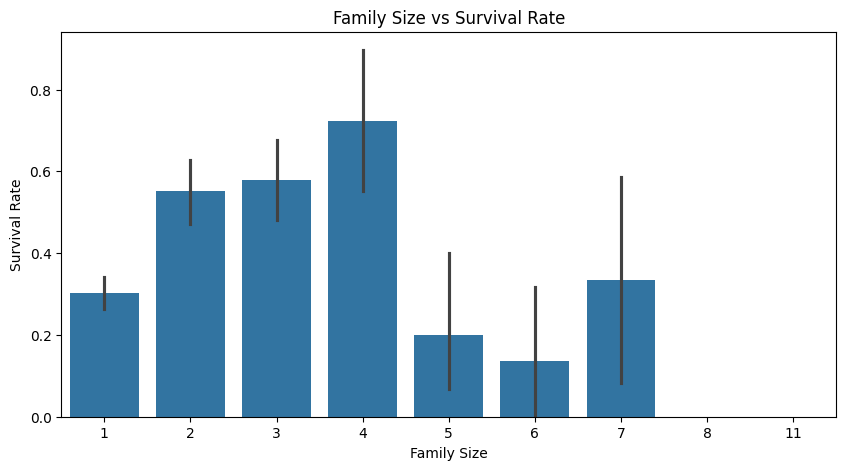

In [103]:
plt.figure(figsize=(10, 5))

sns.barplot(data=df, x="FamilySize", y="Survived")

plt.title("Family Size vs Survival Rate")
plt.xlabel("Family Size")
plt.ylabel("Survival Rate")
plt.show()

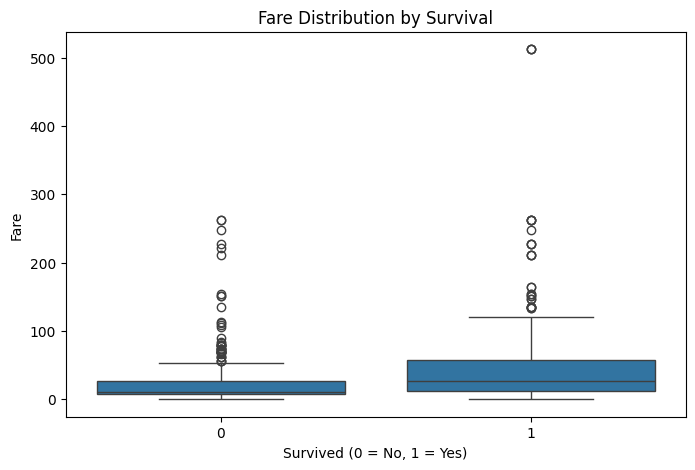

In [104]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="Survived", y="Fare")

plt.title("Fare Distribution by Survival")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Fare")
plt.show()

In [105]:
survival_analysis = df.pivot_table(
    index="Pclass",
    columns="Sex",
    values="Survived",
    aggfunc="mean"
) * 100

print(survival_analysis.round(2))

Sex     female   male
Pclass               
1        96.81  36.89
2        92.11  15.74
3        50.00  13.54


## 7. Key Findings

1. **Overall Survival:** Out of 891 passengers, 342 survived (38.38%), while 549 did not survive (61.62%).

2. **Gender:** Female passengers had a much higher survival rate (74.20%) than male passengers (18.89%).

3. **Passenger Class:** First-class passengers had the highest survival rate (62.96%), followed by second-class (47.28%) and third-class passengers (24.24%).

4. **Age:** Most passengers were adults, with the 30–40 age range appearing prominently in the age distribution.

5. **Fare:** Passengers who paid higher fares generally showed better survival outcomes. However, fare and passenger class are related factors.

6. **Family Size:** Passengers travelling in small families had a higher survival rate (approximately 57%) than those travelling alone (31%) or in large families (16%).

7. **Cabin Availability:** Passengers with recorded cabin information had a higher observed survival rate than those without it. This relationship may partly reflect differences in passenger class.

8. **Missing Values:** The Age and Embarked columns were cleaned by filling missing values with their median and mode, respectively. Cabin information was largely missing, so a separate feature was created to indicate cabin availability.

## 8. Conclusion

This Exploratory Data Analysis (EDA) examined the Titanic passenger dataset to understand the factors associated with passenger survival.

The analysis revealed that gender and passenger class had strong relationships with survival outcomes. Female passengers and first-class passengers had higher survival rates than male passengers and those travelling in lower classes.

Fare and family size also showed interesting patterns. Passengers travelling in small families had better observed survival rates than those travelling alone or in large families. Cabin availability was also associated with survival, although this may partly reflect differences in passenger class.

The project also involved handling missing values, creating new features, performing statistical analysis, and visualizing patterns using Python libraries such as Pandas, Matplotlib, and Seaborn.

Overall, this project demonstrates how Exploratory Data Analysis can help uncover patterns in real-world datasets. These findings describe associations in the available data and do not establish causation.